# Семинар 4. Сопряжённая система и градиент по управлению

На прошлом семинаре задача оптимального управления была сведена к конечномерной оптимизации:
$$
u=(u_0,\ldots,u_{N-1})
\quad\longmapsto\quad
J(u).
$$

`scipy.optimize` работал с функцией `objective(u)`. Теперь разберём, как получить её градиент из самой задачи оптимального управления.

Будем использовать стандартную схему через функцию Гамильтона-Понтрягина. После этого сравним сопряжённый градиент с конечными разностями и используем его в простом методе проекции градиента.

Задача:
$$
\dot x_1=x_2,\qquad
\dot x_2=u,\qquad |u|\le1,
$$
$$
x(0)=(0,0),\qquad T=2,
$$
$$
J=
100(x_1(T)-1)^2+
20x_2(T)^2+
0.05\int_0^T u^2(t)\,dt.
$$

## 0. Импорт

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from time import perf_counter
from scipy.optimize import minimize

## 1. Дискретизация управления и динамики

Управление считаем кусочно-постоянным:
$$
u(t)=u_k,\qquad t\in[t_k,t_{k+1}),
$$
$$
h=\frac{T}{N}.
$$

Для двойного интегратора переход за один интервал можно записать точно:
$$
x_{k+1}=Ax_k+Bu_k,
$$
где
$$
A=
\begin{pmatrix}
1 & h\\
0 & 1
\end{pmatrix},
\qquad
B=
\begin{pmatrix}
h^2/2\\
h
\end{pmatrix}.
$$

Возьмём $N=40$.

In [2]:
T = 2.0
N = 100

x0 = np.array([0.0, 0.0])
x_target = np.array([1.0, 0.0])

w1 = 100.0
w2 = 20.0
lam = 0.05


def matrices(N):
    h = T / N

    A = np.array([
        [1.0, h],
        [0.0, 1.0],
    ])

    B = np.array([
        0.5 * h**2,
        h,
    ])

    return h, A, B


def simulate(u):
    h, A, B = matrices(len(u))

    x = np.zeros((len(u) + 1, 2))
    x[0] = x0

    for k in range(len(u)):
        x[k + 1] = A @ x[k] + B * u[k]

    return x


def objective(u):
    h, _, _ = matrices(len(u))
    x = simulate(u)

    e = x[-1] - x_target

    return (
        w1 * e[0]**2
        + w2 * e[1]**2
        + lam * h * np.sum(u**2)
    )

### Численный ориентир

Сначала решим задачу `L-BFGS-B`. Результат понадобится только как ориентир при сравнении с собственным методом.

In [3]:
bounds = [(-1.0, 1.0)] * N

res_ref = minimize(
    objective,
    np.zeros(N),
    method="L-BFGS-B",
    bounds=bounds,
    options={
        "maxiter": 1000,
        "ftol": 1e-12,
    },
)

u_ref = res_ref.x
x_ref = simulate(u_ref)

print("success:", res_ref.success)
print("J* ≈", res_ref.fun)
print("x(T) ≈", x_ref[-1])
print("iterations:", res_ref.nit)

success: True
J* ≈ 0.08963306882637903
x(T) ≈ [0.99758764 0.0119886 ]
iterations: 34


## 2. Конечные разности

Градиент можно получить, не используя устройство задачи. Для $k$-й компоненты:
$$
\frac{\partial J}{\partial u_k}
\approx
\frac{
J(u+\varepsilon e_k)-J(u-\varepsilon e_k)
}{
2\varepsilon
}.
$$

Для центральной разности требуется два вычисления функционала на каждую компоненту управления.

**Вопрос до запуска:** сколько раз будет вычислена динамика для одного градиента при $N=100$?

In [4]:
def finite_difference_gradient(u, eps=1e-6):
    grad = np.zeros_like(u)

    for k in range(len(u)):
        u_plus = u.copy()
        u_minus = u.copy()

        u_plus[k] += eps
        u_minus[k] -= eps

        grad[k] = (
            objective(u_plus) - objective(u_minus)
        ) / (2 * eps)

    return grad


k = np.arange(N)
u_test = 0.2 * np.sin(2 * np.pi * (k + 0.5) / N)

start = perf_counter()
g_fd = finite_difference_gradient(u_test)
time_fd = perf_counter() - start

print("Время finite differences:", time_fd)
print("||g_fd|| =", np.linalg.norm(g_fd))

Время finite differences: 0.017452833999413997
||g_fd|| = 40.30460589681616


## 3. Непрерывная сопряжённая система

Рассмотрим сначала непрерывную задачу в общем виде:
$$
\dot x=f(x,u),
$$
$$
J(u)=\Phi(x(T))+\int_0^T L(x,u)\,dt.
$$

Для задачи минимизации введём функцию Гамильтона-Понтрягина
$$
H(x,u,p)=L(x,u)+p^{\mathsf T}f(x,u).
$$

Сопряжённая переменная определяется системой
$$
\dot p=-H_x,
$$
с терминальным условием
$$
p(T)=\Phi_x(x(T)).
$$

После решения прямой задачи для $x(t)$ и обратной задачи для $p(t)$ градиент функционала по управлению имеет вид
$$
\boxed{
g(t)=\nabla_u J(t)=H_u(x(t),u(t),p(t))
}.
$$

Эта формула будет использоваться дальше. Подробный вывод через вариации здесь не нужен.

### Для двойного интегратора

В нашей задаче
$$
L(x,u)=\lambda u^2,
$$
$$
f(x,u)=
\begin{pmatrix}
x_2\\
u
\end{pmatrix},
$$
поэтому
$$
H=
\lambda u^2+p_1x_2+p_2u.
$$

Сопряжённая система:
$$
\dot p_1=0,
$$
$$
\dot p_2=-p_1.
$$

Терминальное условие:
$$
p(T)=
\begin{pmatrix}
2w_1(x_1(T)-1)\\
2w_2x_2(T)
\end{pmatrix}.
$$

Градиент:
$$
\boxed{
g(t)=2\lambda u(t)+p_2(t)
}.
$$

Если ограничений на управление нет, условие стационарности $H_u=0$ даёт
$$
u^*(t)=-\frac{p_2(t)}{2\lambda}.
$$

При ограничении $|u|\le1$ условие минимума гамильтониана даёт
$$
u^*(t)=
\operatorname{clip}
\left(
-\frac{p_2(t)}{2\lambda},
-1,1
\right).
$$

Это тот же тип насыщения, который мы наблюдали численно на прошлом семинаре.

## 4. От непрерывного градиента к дискретному

В коде переменными являются не значения функции $u(t)$ в каждой точке, а коэффициенты кусочно-постоянного управления $u_k$.

Поэтому $k$-я компонента дискретного градиента равна интегралу непрерывного градиента по интервалу:
$$
\frac{\partial J}{\partial u_k}
=
\int_{t_k}^{t_{k+1}}
\left(
2\lambda u_k+p_2(t)
\right)\,dt.
$$

Для двойного интегратора сопряжённая переменная $p_2(t)$ на каждом интервале линейна. При точном переходе динамики получаем
$$
p_k=A^{\mathsf T}p_{k+1},
$$
и
$$
\boxed{
\frac{\partial J}{\partial u_k}
=
2\lambda h\,u_k+
B^{\mathsf T}p_{k+1}
}.
$$

Обратите внимание на множитель $h$. Непрерывный градиент $g(t)$ и градиент по коэффициентам дискретного управления - не одно и то же.

In [5]:
def adjoint_gradient(u):
    h, A, B = matrices(len(u))
    x = simulate(u)

    p = np.zeros((len(u) + 1, 2))
    grad = np.zeros(len(u))

    e = x[-1] - x_target

    p[-1] = np.array([
        2 * w1 * e[0],
        2 * w2 * e[1],
    ])

    for k in range(len(u) - 1, -1, -1):
        grad[k] = (
            2 * lam * h * u[k]
            + B @ p[k + 1]
        )

        p[k] = A.T @ p[k + 1]

    return grad, p

Сравним сопряжённый градиент с конечными разностями.

In [6]:
start = perf_counter()
g_adj, p = adjoint_gradient(u_test)
time_adj = perf_counter() - start

relative_error = (
    np.linalg.norm(g_fd - g_adj)
    / np.linalg.norm(g_adj)
)

print("Время finite differences:", time_fd)
print("Время adjoint:", time_adj)
print("Относительная ошибка:", relative_error)

Время finite differences: 0.017452833999413997
Время adjoint: 0.00023991597117856145
Относительная ошибка: 1.4770717643358108e-09


In [7]:
time_fd = %timeit -o -q finite_difference_gradient(u_test)
time_adj = %timeit -o -q adjoint_gradient(u_test)

g_adj, p = adjoint_gradient(u_test)

relative_error = (
    np.linalg.norm(g_fd - g_adj)
    / np.linalg.norm(g_adj)
)

print("Среднее время finite differences:", time_fd.average)
print("Среднее время adjoint:", time_adj.average)
print("Ускорение:", time_fd.average / time_adj.average)
print("Относительная ошибка:", relative_error)

Среднее время finite differences: 0.017535535116995953
Среднее время adjoint: 0.00017715611728573484
Ускорение: 98.98351457270263
Относительная ошибка: 1.4770717643358108e-09


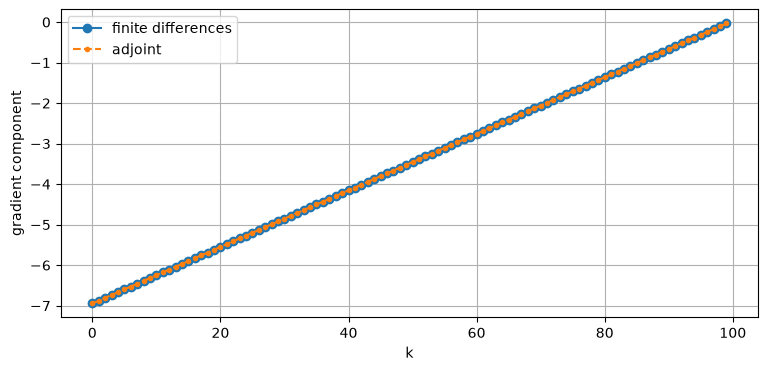

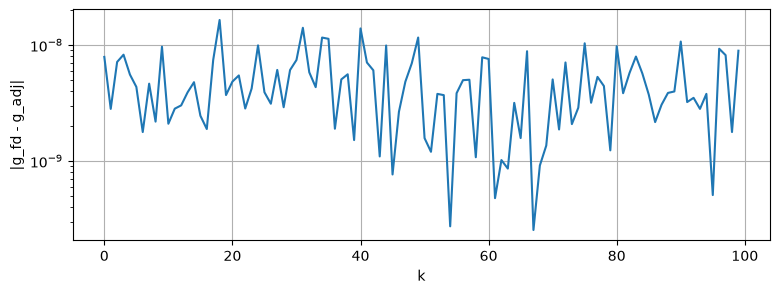

In [8]:
plt.figure(figsize=(9, 4))
plt.plot(g_fd, "o-", label="finite differences")
plt.plot(g_adj, ".--", label="adjoint")
plt.xlabel("k")
plt.ylabel("gradient component")
plt.grid()
plt.legend()
plt.show()

plt.figure(figsize=(9, 3))
plt.plot(np.abs(g_fd - g_adj))
plt.yscale("log")
plt.xlabel("k")
plt.ylabel("|g_fd - g_adj|")
plt.grid()
plt.show()

### Проверка

Объясните:

1. почему сопряжённая система решается назад;
2. почему в формуле дискретного градиента стоит $p_{k+1}$;
3. откуда появляется множитель $h$;
4. почему совпадение с finite differences является важной проверкой реализации.

## 5. Directional derivative test

Для больших задач проверять конечными разностями каждую компоненту дорого.

Берём направление $v$ и сравниваем
$$
\nabla J(u)^{\mathsf T}v
$$
с
$$
\frac{
J(u+\varepsilon v)-J(u-\varepsilon v)
}{
2\varepsilon
}.
$$

Для каждого $\varepsilon$ требуется только два вычисления `objective`.

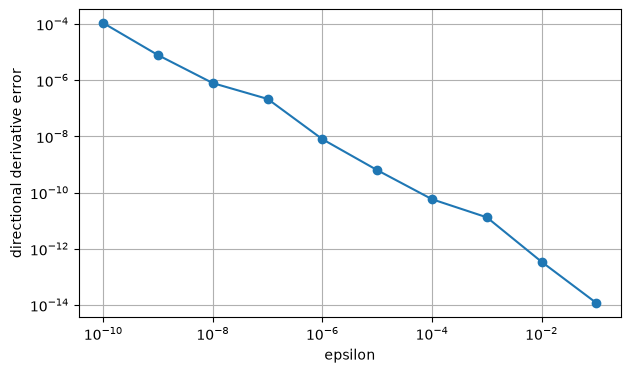

In [9]:
rng = np.random.default_rng(42)

v = rng.normal(size=N)
v /= np.linalg.norm(v)

exact_directional = g_adj @ v

eps_values = 10.0 ** (-np.arange(1, 11))
errors = []

for eps in eps_values:
    fd_directional = (
        objective(u_test + eps * v)
        - objective(u_test - eps * v)
    ) / (2 * eps)

    errors.append(
        abs(fd_directional - exact_directional)
    )

plt.figure(figsize=(7, 4))
plt.loglog(eps_values, errors, "o-")
plt.xlabel("epsilon")
plt.ylabel("directional derivative error")
plt.grid()
plt.show()

Ошибка сначала уменьшается вместе с $\varepsilon$, а затем начинает расти из-за ошибок округления.

**Вопрос:** почему нельзя брать $\varepsilon$ сколь угодно маленьким?

## 6. Стоимость вычисления градиента

Сравним два способа при
$$
N=20,\;40,\;80,\;160.
$$

В этой реализации одна симуляция стоит $O(N)$.

- finite differences требует $O(N)$ симуляций, поэтому общая стоимость близка к $O(N^2)$;
- сопряжённый метод использует один прямой и один обратный проход, поэтому его стоимость близка к $O(N)$.

Абсолютные времена небольшие и зависят от компьютера; важна тенденция.

In [10]:
rows = []

for N_test in [20, 40, 80, 160]:
    k = np.arange(N_test)

    u = 0.2 * np.sin(
        2 * np.pi * (k + 0.5) / N_test
    )

    start = perf_counter()
    g1 = finite_difference_gradient(u)
    t_fd = perf_counter() - start

    start = perf_counter()
    g2, _ = adjoint_gradient(u)
    t_adj = perf_counter() - start

    rows.append({
        "N": N_test,
        "finite_diff_s": t_fd,
        "adjoint_s": t_adj,
        "speedup": t_fd / t_adj,
        "relative_error":
            np.linalg.norm(g1 - g2)
            / np.linalg.norm(g2),
    })

timing = pd.DataFrame(rows)
timing

,N,finite_diff_s,adjoint_s,speedup,relative_error
0,20,0.000858,0.000045,19.144061,3.702174e-10
1,40,0.003394,0.000077,43.976629,8.550777e-10
2,80,0.011472,0.000148,77.271855,1.774946e-09
3,160,0.045343,0.000290,156.558900,2.414667e-09


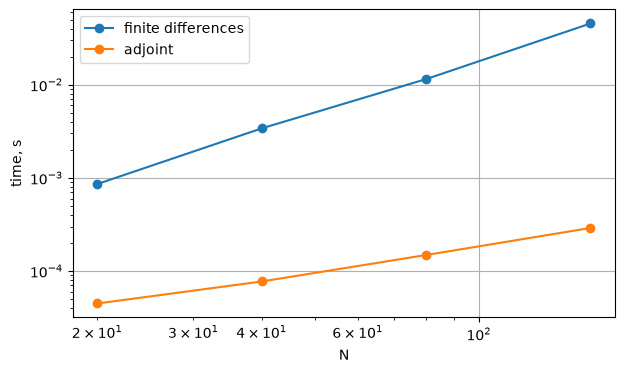

In [11]:
plt.figure(figsize=(7, 4))

plt.loglog(
    timing["N"],
    timing["finite_diff_s"],
    "o-",
    label="finite differences",
)

plt.loglog(
    timing["N"],
    timing["adjoint_s"],
    "o-",
    label="adjoint",
)

plt.xlabel("N")
plt.ylabel("time, s")
plt.grid()
plt.legend()
plt.show()

## 7. Метод проекции градиента

Для
$$
U=[-1,1]^N
$$
проекция выполняется покомпонентно:
$$
P_U(u)=\operatorname{clip}(u,-1,1).
$$

Итерация:
$$
u^{m+1}
=
P_U
\left(
u^m-\alpha\nabla J(u^m)
\right).
$$

Это простой метод. В отличие от `L-BFGS-B`, каждый его шаг полностью прозрачен.

In [12]:
def projected_gradient(
    alpha=0.06,
    maxiter=1000,
):
    u = np.zeros(N)
    history = []

    for iteration in range(maxiter):
        history.append(objective(u))

        grad, _ = adjoint_gradient(u)

        u = np.clip(
            u - alpha * grad,
            -1.0,
            1.0,
        )

    history.append(objective(u))

    return u, np.array(history)


u_pg, history_pg = projected_gradient()
x_pg = simulate(u_pg)

print("Projected gradient:")
print("J =", objective(u_pg))
print("x(T) =", x_pg[-1])

print()
print("L-BFGS-B:")
print("J =", res_ref.fun)
print("x(T) =", x_ref[-1])

Projected gradient:
J = 0.09694227772714821
x(T) = [0.99460033 0.02721102]

L-BFGS-B:
J = 0.08963306882637903
x(T) = [0.99758764 0.0119886 ]


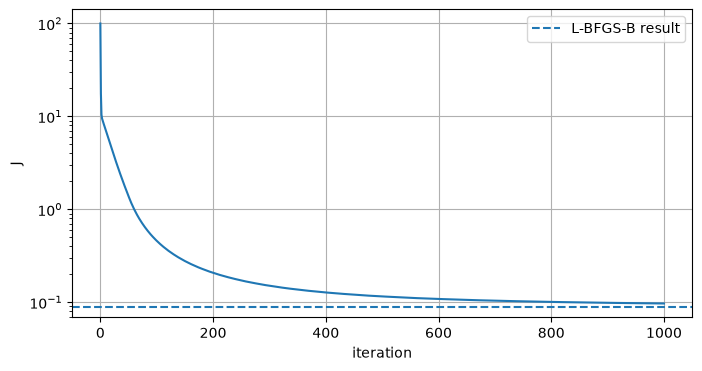

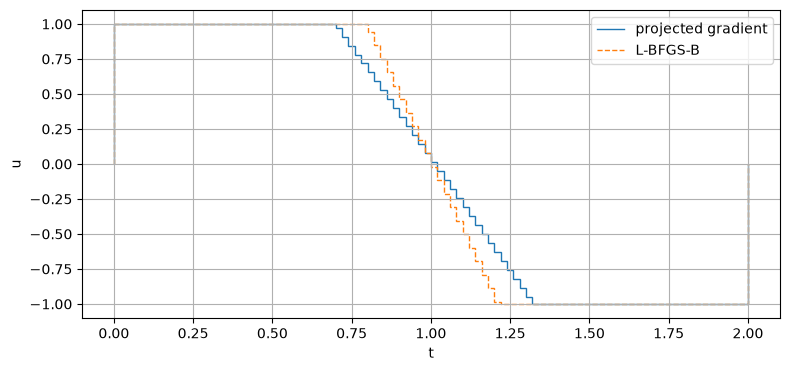

In [13]:
plt.figure(figsize=(8, 4))

plt.semilogy(history_pg)
plt.axhline(
    res_ref.fun,
    linestyle="--",
    label="L-BFGS-B result",
)

plt.xlabel("iteration")
plt.ylabel("J")
plt.grid()
plt.legend()
plt.show()


t_edges = np.linspace(0, T, N + 1)

plt.figure(figsize=(9, 4))

plt.stairs(
    u_pg,
    t_edges,
    label="projected gradient",
)

plt.stairs(
    u_ref,
    t_edges,
    linestyle="--",
    label="L-BFGS-B",
)

plt.xlabel("t")
plt.ylabel("u")
plt.ylim(-1.1, 1.1)
plt.grid()
plt.legend()
plt.show()

Проверьте также
$$
\alpha=0.01,\qquad0.03,\qquad0.06.
$$

Малый шаг даёт медленную сходимость. При слишком большом шаге функционал может перестать убывать.

## 8. Общий вид

Для задачи
$$
\dot x=f(x,u),
$$
$$
J=
\Phi(x(T))
+
\int_0^T L(x,u)\,dt
$$
вводится
$$
H=L+p^{\mathsf T}f.
$$

Основные формулы:
$$
\dot p=-H_x,
$$
$$
p(T)=\Phi_x(x(T)),
$$
$$
g(t)=H_u.
$$

Для ограниченного управления $u(t)\in U$ условие Понтрягина имеет вид
$$
u^*(t)\in
\operatorname*{arg\,min}_{u\in U}
H(x^*(t),u,p(t)).
$$

Для численного алгоритма непрерывная задача затем дискретизируется. Формула дискретного градиента должна быть согласована с выбранной дискретизацией динамики.

# Домашняя работа - срок 1 неделя

## 1. Проверка градиента при разных $N$

Для
$$
N=20,\quad40,\quad80,\quad160
$$
сравните finite-difference и adjoint gradient.

Сохраните:

- относительную ошибку;
- время finite differences;
- время adjoint;
- отношение времён.

Оформите результаты в таблицу и постройте график времени от $N$ в логарифмических осях. Коротко объясните результат.

,N,relative_error,finite_diff_s,adjoint_s,speedup
0,20,3.702174e-10,0.000839,0.000040,21.027298
1,40,8.550777e-10,0.003029,0.000103,29.289535
2,80,1.774946e-09,0.011293,0.000144,78.537743
3,160,2.414667e-09,0.043887,0.000284,154.407276


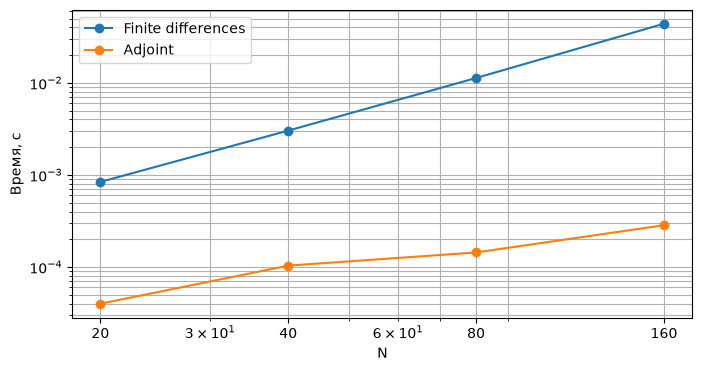

In [14]:
# Ваш код для задания 1
from timeit import repeat

rows = []

for N_test in [20, 40, 80, 160]:
    k = np.arange(N_test)
    u = 0.2 * np.sin(2 * np.pi * (k + 0.5) / N_test)

    g_fd_test = finite_difference_gradient(u)
    g_adj_test, _ = adjoint_gradient(u)

    t_fd = np.mean(repeat(
        lambda: finite_difference_gradient(u),
        number=3, repeat=5
    )) / 3

    t_adj = np.mean(repeat(
        lambda: adjoint_gradient(u),
        number=100, repeat=5
    )) / 100

    rows.append({
        "N": N_test,
        "relative_error": np.linalg.norm(g_fd_test - g_adj_test)
                          / np.linalg.norm(g_adj_test),
        "finite_diff_s": t_fd,
        "adjoint_s": t_adj,
        "speedup": t_fd / t_adj,
    })

timing_hw1 = pd.DataFrame(rows)
display(timing_hw1)

plt.figure(figsize=(8, 4))

plt.loglog(
    timing_hw1["N"], timing_hw1["finite_diff_s"],
    "o-", label="Finite differences"
)
plt.loglog(
    timing_hw1["N"], timing_hw1["adjoint_s"],
    "o-", label="Adjoint"
)

plt.xlabel("N")
plt.ylabel("Время, с")
plt.xticks([20, 40, 80, 160], [20, 40, 80, 160])
plt.grid(True, which="both")
plt.legend()
plt.show()

<span style="color:red">Ответ:</span>

относительная ошибка между градиентами составляет от $3.70\cdot10^{-10}$ до $2.41\cdot10^{-9}$, что подтверждает согласованность результатов двух методов. Время вычисления градиента методом конечных разностей растёт приблизительно как $O(N^2)$, а сопряжённым методом — как $O(N)$. При увеличении $N$ от 20 до 160 ускорение сопряжённого метода возрастает примерно от 20 до 150 раз.

## 2. Выбор $\varepsilon$

Для $N=40$ выполните directional derivative test при
$$
\varepsilon=10^{-1},10^{-2},\ldots,10^{-12}.
$$

Постройте ошибку в логарифмических осях.

Укажите:

1. где ошибка уменьшается;
2. при каком порядке $\varepsilon$ она примерно минимальна;
3. почему затем начинается рост.

,epsilon,error
0,1.000000e-01,9.592327e-14
1,1.000000e-02,1.659117e-12
2,1.000000e-03,2.107825e-11
3,1.000000e-04,1.281357e-10
4,1.000000e-05,1.051841e-09
5,1.000000e-06,8.867811e-09
6,1.000000e-07,5.343043e-09
7,1.000000e-08,1.367655e-07
8,1.000000e-09,1.284320e-06
9,1.000000e-10,3.424282e-05


Минимальная ошибка: 9.592326932761353e-14
Оптимальное epsilon: 0.1


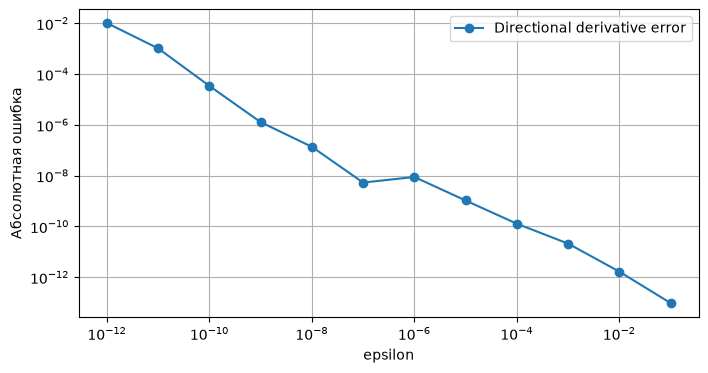

In [18]:
# Ваш код для задания 2
N_test = 40
k = np.arange(N_test)
u = 0.2 * np.sin(2 * np.pi * (k + 0.5) / N_test)

rng = np.random.default_rng(42)
v = rng.normal(size=N_test)
v /= np.linalg.norm(v)

g_adj, _ = adjoint_gradient(u)
exact_directional = g_adj @ v

eps_values = 10.0 ** (-np.arange(1, 13))
errors = []

for eps in eps_values:
    fd_directional = (
        objective(u + eps * v)
        - objective(u - eps * v)
    ) / (2 * eps)

    errors.append(abs(fd_directional - exact_directional))

results = pd.DataFrame({
    "epsilon": eps_values,
    "error": errors,
})

display(results)

best_idx = np.argmin(errors)
print("Минимальная ошибка:", errors[best_idx])
print("Оптимальное epsilon:", eps_values[best_idx])

plt.figure(figsize=(8, 4))
plt.loglog(eps_values, errors, "o-", label="Directional derivative error")
plt.xlabel("epsilon")
plt.ylabel("Абсолютная ошибка")
plt.grid(True, which="both")
plt.legend()
plt.show()

<span style="color:red">Ответ:</span>

1. ошибка в целом уменьшается при увеличении $\varepsilon$ от $10^{-12}$ до $10^{-1}$

2. минимальная ошибка порядка $10^{-13}$ при $\varepsilon=10^{-1}$

3. при уменьшении $\varepsilon$ ошибка возрастает из-за накопления ошибок округления при вычитании близких значений функционала и последующем делении на малое число. Поскольку функционал квадратичен по управлению, центральная разность теоретически точна и ошибка аппроксимации отсутствует

## 3. Выбор шага projected gradient

Запустите метод при
$$
\alpha=0.01,\quad0.03,\quad0.06.
$$

На одном рисунке постройте три зависимости
$$
m\mapsto J_m
$$
и горизонтальную линию с результатом `L-BFGS-B`.

Сравните скорость сходимости и конечное значение функционала.

α = 0.01: J = 0.24943753
α = 0.03: J = 0.11560645
α = 0.06: J = 0.09694228
L-BFGS-B: J = 0.08963307


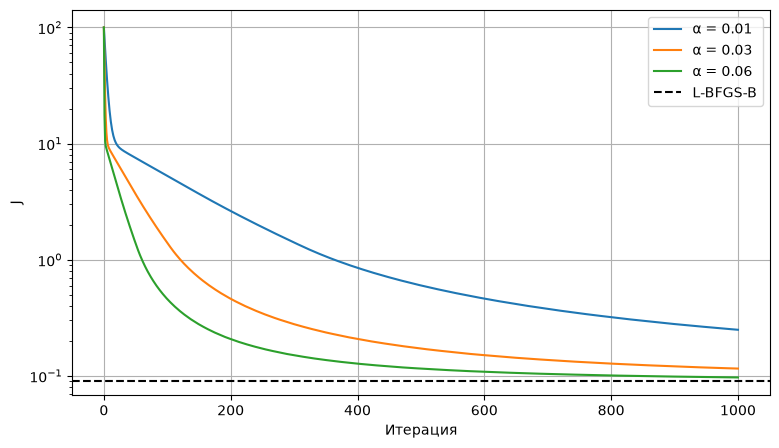

In [19]:
# Ваш код для задания 3
alphas = [0.01, 0.03, 0.06]

plt.figure(figsize=(9, 5))

for alpha in alphas:
    u, history = projected_gradient(alpha=alpha, maxiter=1000)

    plt.semilogy(history, label=f"α = {alpha}")
    print(f"α = {alpha}: J = {history[-1]:.8f}")

plt.axhline(
    res_ref.fun,
    color="black",
    linestyle="--",
    label="L-BFGS-B",
)

print(f"L-BFGS-B: J = {res_ref.fun:.8f}")

plt.xlabel("Итерация")
plt.ylabel("J")
plt.grid(True)
plt.legend()
plt.show()

<span style="color:red">Ответ:</span>

при увеличении шага $\alpha$ скорость сходимости метода проекции градиента возрастает. После 1000 итераций получены значения $J=0.24943753$, $J=0.11560645$ и $J=0.09694228$ для $\alpha=0.01$, $0.03$ и $0.06$ соответственно. Наилучший результат среди рассмотренных шагов достигается при $\alpha=0.06$, однако он уступает L-BFGS-B, для которого $J=0.08963307$

## 4. Маятник

Рассмотрим
$$
\dot\theta=\omega,
$$
$$
\dot\omega=-\sin\theta+u.
$$

Параметры:
$$
T=5,\qquad
(\theta(0),\omega(0))=(0,0),
$$
$$
(\theta_{\mathrm{target}},\omega_{\mathrm{target}})
=
(\pi,0),
$$
$$
J=
20(\theta(T)-\pi)^2+
5\omega(T)^2+
0.05\int_0^T u^2(t)\,dt.
$$

### Теоретическая часть

1. Выпишите функцию Гамильтона-Понтрягина.
2. Получите сопряжённую систему.
3. Выпишите терминальное условие.
4. Получите непрерывный градиент $H_u$.

### Численная часть

Используйте явный Euler:
$$
\theta_{k+1}
=
\theta_k+h\omega_k,
$$
$$
\omega_{k+1}
=
\omega_k+h(-\sin\theta_k+u_k).
$$

Возьмите
$$
N=100.
$$

Для дискретного шага
$$
F_x=
\begin{pmatrix}
1 & h\\
-h\cos\theta_k & 1
\end{pmatrix},
\qquad
F_u=
\begin{pmatrix}
0\\
h
\end{pmatrix}.
$$

Требуется:

1. написать `simulate_pendulum`;
2. написать `objective_pendulum`;
3. реализовать дискретный adjoint gradient;
4. проверить его directional derivative test на случайном управлении с небольшими компонентами.

Оптимизировать маятник пока не требуется.

In [20]:
T_p = 5.0
N_p = 100
h_p = T_p / N_p

x0_p = np.array([0.0, 0.0])
x_target_p = np.array([np.pi, 0.0])

w_theta = 20.0
w_omega = 5.0
lam_p = 0.05


def simulate_pendulum(u):
    x = np.zeros((N_p + 1, 2))
    x[0] = x0_p

    for k in range(N_p):
        theta, omega = x[k]

        x[k + 1] = [
            theta + h_p * omega,
            omega + h_p * (-np.sin(theta) + u[k]),
        ]

    return x


def objective_pendulum(u):
    x = simulate_pendulum(u)
    e = x[-1] - x_target_p

    return (
        w_theta * e[0]**2
        + w_omega * e[1]**2
        + lam_p * h_p * np.sum(u**2)
    )


def adjoint_gradient_pendulum(u):
    x = simulate_pendulum(u)

    p = np.zeros((N_p + 1, 2))
    grad = np.zeros(N_p)

    e = x[-1] - x_target_p

    p[-1] = np.array([
        2 * w_theta * e[0],
        2 * w_omega * e[1],
    ])

    for k in range(N_p - 1, -1, -1):
        Fx = np.array([
            [1.0, h_p],
            [-h_p * np.cos(x[k, 0]), 1.0],
        ])

        grad[k] = (
            2 * lam_p * h_p * u[k]
            + h_p * p[k + 1, 1]
        )

        p[k] = Fx.T @ p[k + 1]

    return grad, p

In [21]:
rng = np.random.default_rng(42)

u_test_p = rng.uniform(-0.1, 0.1, N_p)

v = rng.normal(size=N_p)
v /= np.linalg.norm(v)

g_adj_p, p_p = adjoint_gradient_pendulum(u_test_p)
exact_directional = g_adj_p @ v

eps_values = 10.0 ** (-np.arange(2, 7))
errors = []

for eps in eps_values:
    fd_directional = (
        objective_pendulum(u_test_p + eps * v)
        - objective_pendulum(u_test_p - eps * v)
    ) / (2 * eps)

    errors.append(abs(fd_directional - exact_directional))

results_p = pd.DataFrame({
    "epsilon": eps_values,
    "error": errors,
})

display(results_p)

print("Сопряжённая производная:", exact_directional)
print("Минимальная ошибка:", min(errors))

,epsilon,error
0,0.010000,6.281894e-09
1,0.001000,7.032952e-11
2,0.000100,1.555946e-10
3,0.000010,1.008246e-09
4,0.000001,4.128395e-10


Сопряжённая производная: -2.171744568655484
Минимальная ошибка: 7.032951998553472e-11


<span style="color:red">Ответ:</span>

1. функция Гамильтона-Понтрягина:

   $$
   H=0.05u^2+p_1\omega+p_2(-\sin\theta+u)
   $$

2. сопряжённая система:

   $$
   \begin{cases}
   \dot p_1=-H_\theta=p_2\cos\theta\\
   \dot p_2=-H_\omega=-p_1
   \end{cases}
   $$

3. терминальное условие:

   $$
   p(T)=
   \begin{pmatrix}
   40(\theta(T)-\pi)\\
   10\omega(T)
   \end{pmatrix}
   $$

4. непрерывный градиент по управлению:

   $$
   H_u=0.1u+p_2
   $$

<span style="color:red">Вывод:</span>

проверка дискретного сопряжённого градиента методом directional derivative test показала хорошее согласование с конечными разностями. Минимальная абсолютная ошибка составила $7.03\cdot10^{-11}$ при $\varepsilon=10^{-3}$, что подтверждает корректность реализации градиента

## Итог

В нескольких предложениях ответьте:

- почему finite differences плохо масштабируется по числу компонент управления;
- что вычисляет сопряжённая система;
- зачем нужен gradient check;
- чем projected gradient отличается от `L-BFGS-B`;
- что изменилось в формулах после перехода к нелинейному маятнику.

## Перед сдачей

- `Restart Kernel -> Run All`;
- все численные выводы должны получаться из кода;
- повторяющийся код вынесите в функции;
- подпишите оси и легенды.

<span style="color:red">Итог:</span>

1. finite differences плохо масштабируется, поскольку для вычисления градиента требуется $2N$ вычислений функционала, каждое из которых имеет сложность $O(N)$, поэтому общая сложность составляет $O(N^2)$

2. сопряжённая система вычисляет чувствительность функционала к изменениям состояния системы, позволяя получить весь градиент по управлению за один прямой и один обратный проход со сложностью $O(N)$

3. gradient check необходим для проверки корректности вычисленного градиента путём сравнения с конечными разностями, что позволяет обнаружить ошибки в сопряжённой системе и её реализации

4. projected gradient использует шаг в направлении антиградиента с последующей проекцией на допустимое множество, тогда как L-BFGS-B является квазиньютоновским методом, учитывающим приближённую информацию о кривизне функционала и ограничения на переменные

5. при переходе к нелинейному маятнику гамильтониан содержит слагаемое $-\sin\theta$, поэтому сопряжённая система зависит от траектории через $\cos\theta$. В дискретном случае матрица $F_x$ зависит от состояния, а градиент вычисляется с учётом выбранной схемы Эйлера